## C3 · Seaborn

Statistical plots from DataFrames using the data/x/y/hue pattern.

In [890]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

### Setup and the basic pattern

#### Setting a seaborn theme

**C3.01**

`import seaborn as sns; sns.set_theme()`

The `sns.set_theme()` function allows us to give every seaborn plot a consistent, clean style. It is useful once at the top of a notebook. Alternatively, skip it and use matplotlib's default style.

`style="whitegrid"` is another popular choice. The default theme first:

In [891]:
# display the example data
df_penguins[["body_mass_g"]].head()

,body_mass_g
0,3750.0
1,3800.0
2,3250.0
3,NaN
4,3450.0


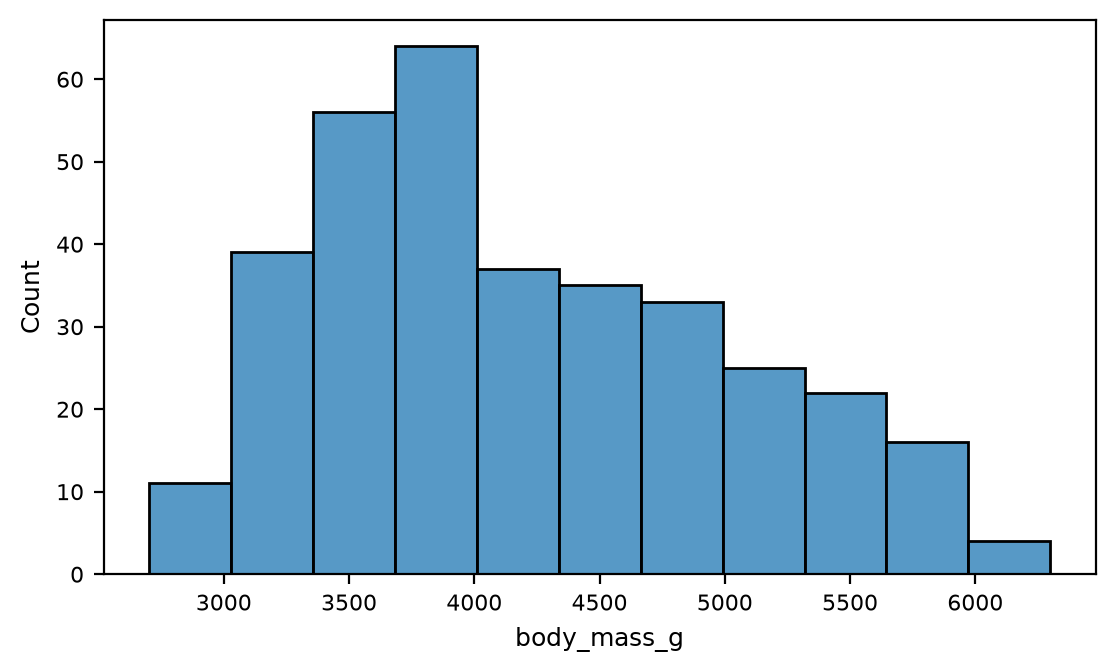

In [892]:
sns.histplot(data=df_penguins, x="body_mass_g");

After `sns.set_theme(style="whitegrid")`, every later plot has grid lines and the new style:

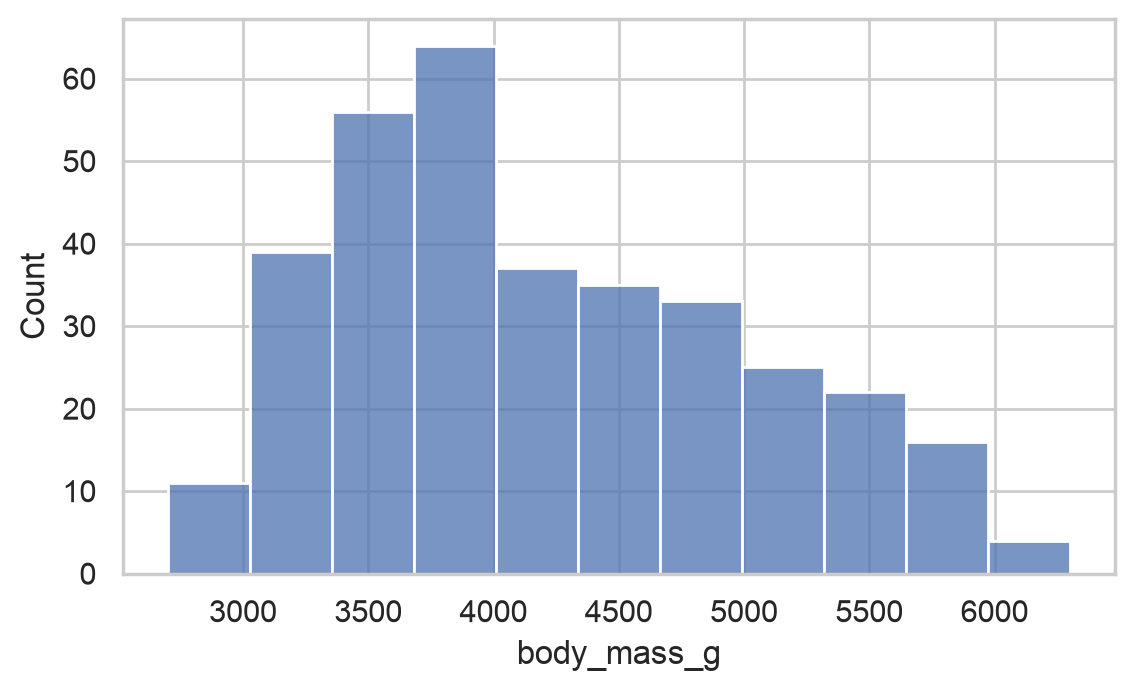

In [893]:
sns.set_theme(style="whitegrid")
sns.histplot(data=df_penguins, x="body_mass_g");

Watch out: `sns.set_theme()` changes **every later plot** in the notebook until it is called again. Calling it with no arguments restores the default theme:

In [894]:
sns.set_theme()

*See also:* Adding a grid (C1) · Choosing a colour palette (C3) · The seaborn data, x, y, hue pattern (C3) · Choosing between `plt` and `ax` (C1)

#### The seaborn data, x, y, hue pattern

**C3.02**

`sns.plotname(data=df, x='col', y='col', hue='col')`

Seaborn's `data=`, `x=`, `y=` and `hue=` arguments allow us to say which DataFrame and which columns to plot, by name. It is useful because every seaborn plot works this way, so once learnt it applies everywhere. Alternatively, matplotlib takes the arrays directly (`plt.scatter(df["a"], df["b"])`).

In [895]:
# display the example data
df_penguins[["flipper_length_mm", "body_mass_g", "species"]].head()

,flipper_length_mm,body_mass_g,species
0,181.0,3750.0,Adelie
1,186.0,3800.0,Adelie
2,195.0,3250.0,Adelie
3,NaN,NaN,Adelie
4,193.0,3450.0,Adelie


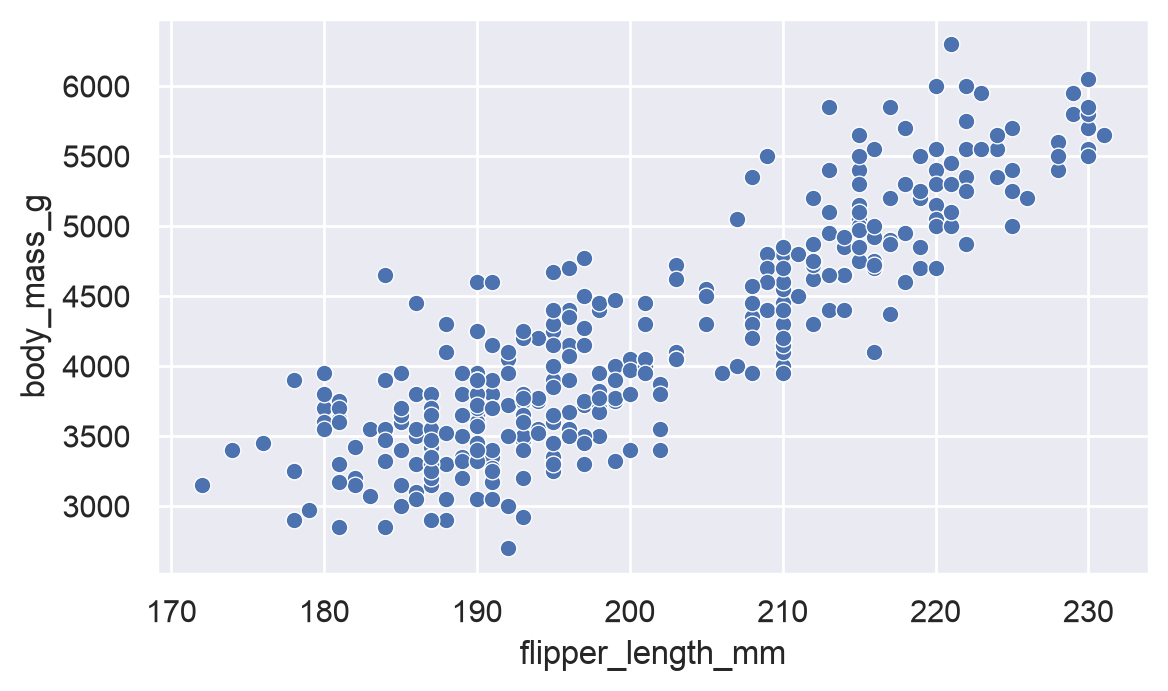

In [896]:
sns.scatterplot(data=df_penguins, x="flipper_length_mm", y="body_mass_g");

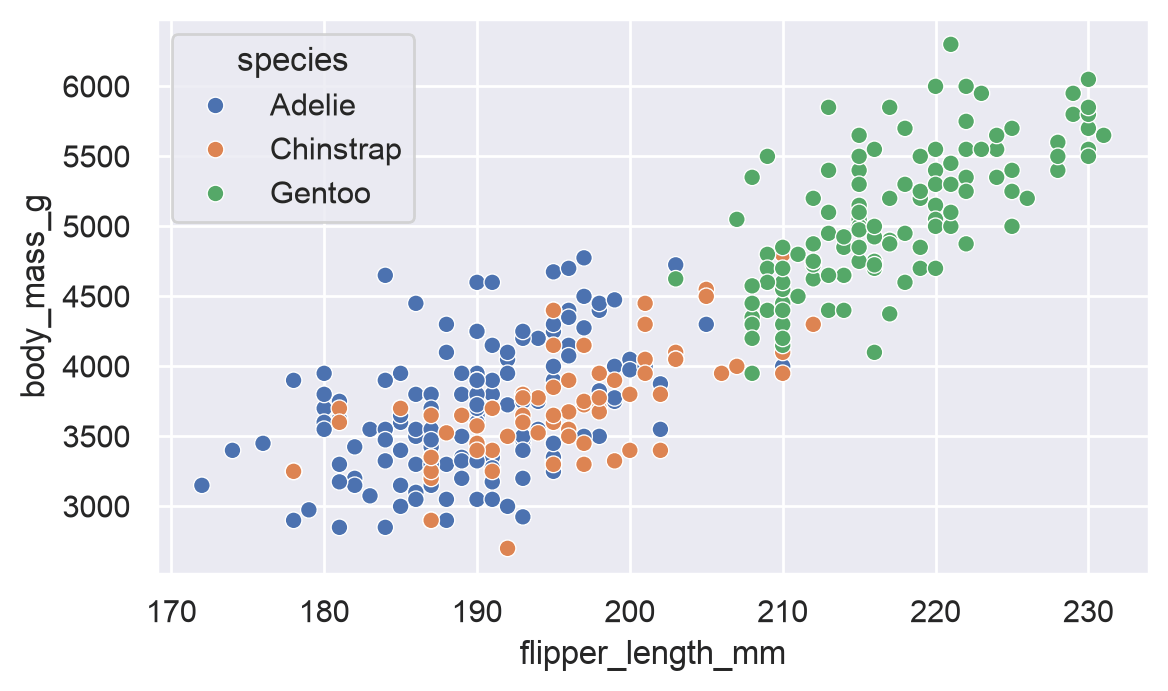

In [897]:
sns.scatterplot(data=df_penguins, x="flipper_length_mm", y="body_mass_g", hue="species");   # one colour per species

*See also:* Drawing a scatter plot (C2) · Colouring points by group (C3) · Labelling a seaborn plot (C3)

#### Labelling a seaborn plot

**C3.03**

`ax = sns.histplot(...); ax.set(title=text, xlabel=text)`

Matplotlib's `plt.title()` and `plt.xlabel()`, or the `ax.set(...)` method on the returned axes, allow us to add titles and labels to a seaborn plot. They are useful because seaborn labels axes with raw column names. Alternatively, rename the columns first so the default labels read well.

In [898]:
# display the example data
df_penguins[["body_mass_g"]].head()

,body_mass_g
0,3750.0
1,3800.0
2,3250.0
3,NaN
4,3450.0


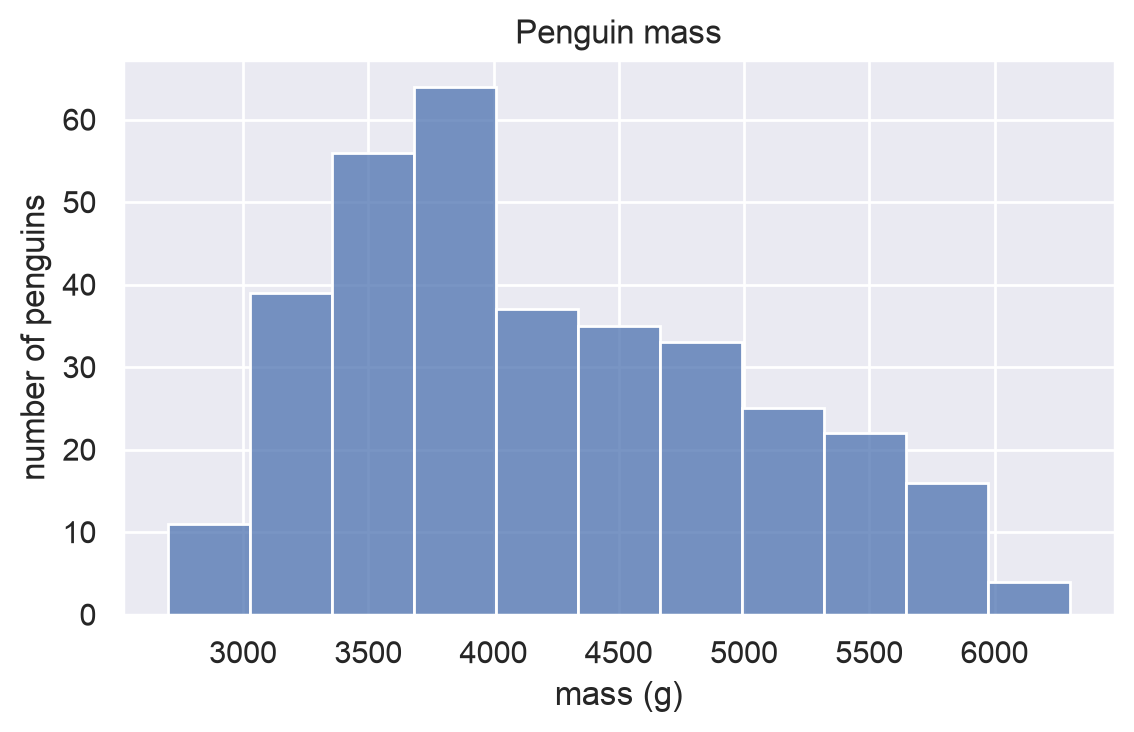

In [899]:
ax = sns.histplot(data=df_penguins, x="body_mass_g")
ax.set(title="Penguin mass", xlabel="mass (g)", ylabel="number of penguins");

*See also:* Adding a title and axis labels (C1) · Drawing panels with `plt.subplots` (C2) · Choosing between `plt` and `ax` (C1)

### Distributions

#### Drawing a histogram with `histplot`

**C3.04**

`sns.histplot(data=df, x='col', bins=n)`

The `sns.histplot()` function allows us to see how the values of a variable are distributed. It is useful for the shape, centre and spread of one variable. Alternatively, `plt.hist` and `Series.plot.hist()` give a similar plot.

In [900]:
# display the example data
df_penguins["flipper_length_mm"].describe().round(0)

count    342.0
mean     201.0
std       14.0
min      172.0
25%      190.0
50%      197.0
75%      213.0
max      231.0
Name: flipper_length_mm, dtype: float64

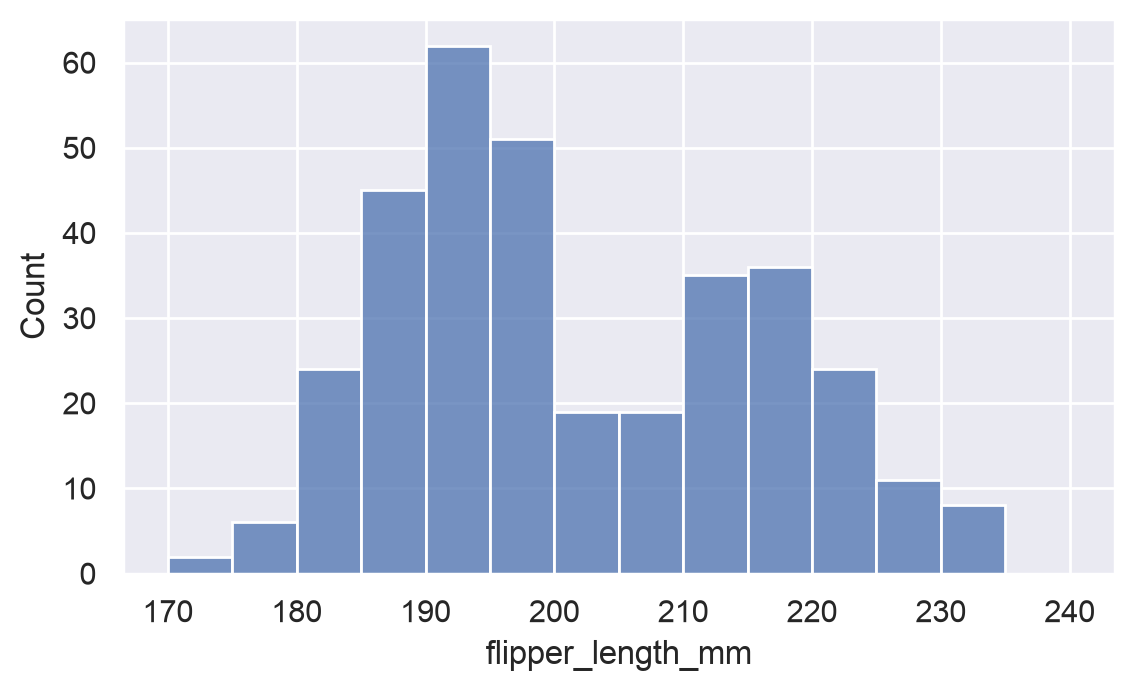

In [901]:
sns.histplot(data=df_penguins, x="flipper_length_mm", bins=np.arange(170, 241, 5));

*See also:* Drawing a histogram (C2) · Adding a smooth density curve (C3) · Centring histogram bars on integers (C3)

#### Centring histogram bars on integers

**C3.05**

`sns.histplot(..., discrete=True)`

The `discrete=True` option allows us to centre one bar on each whole number. It is useful for counts and dice totals, where values cannot lie between integers. Alternatively, `sns.countplot` counts categories directly.

In [902]:
np.random.seed(1)                          # fixed seed, so the output is repeatable

In [903]:
df_rolls = pd.DataFrame({"total": np.random.randint(1, 7, 500) + np.random.randint(1, 7, 500)})
df_rolls.head()

,total
0,7
1,9
2,9
3,6
4,6


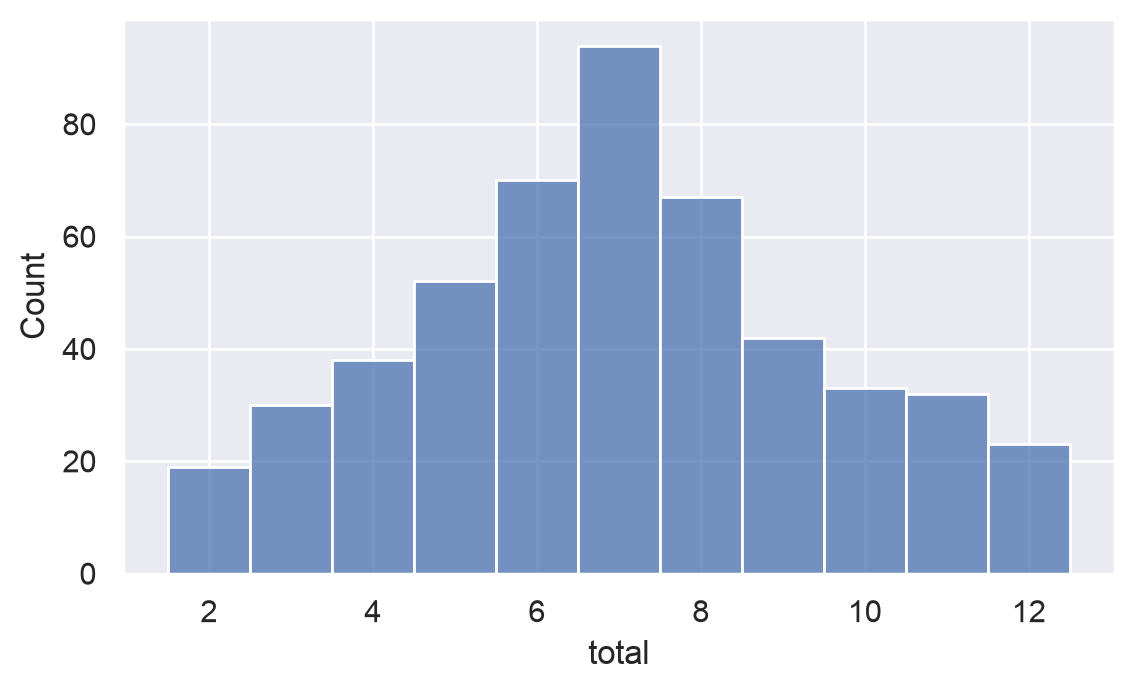

In [904]:
sns.histplot(data=df_rolls, x="total", discrete=True);

*See also:* Drawing a histogram with `histplot` (C3) · Counting categories with `countplot` (C3)

#### Adding a smooth density curve

**C3.06**

`sns.histplot(..., kde=True)`

The `kde=True` option allows us to overlay a smoothed density curve on a histogram. It is useful for seeing the overall shape without being distracted by individual bins. Alternatively, `sns.kdeplot` draws the curve alone.

A histogram shows the counts in bins:

In [905]:
# display the example data
df_penguins[["body_mass_g"]].head()

,body_mass_g
0,3750.0
1,3800.0
2,3250.0
3,NaN
4,3450.0


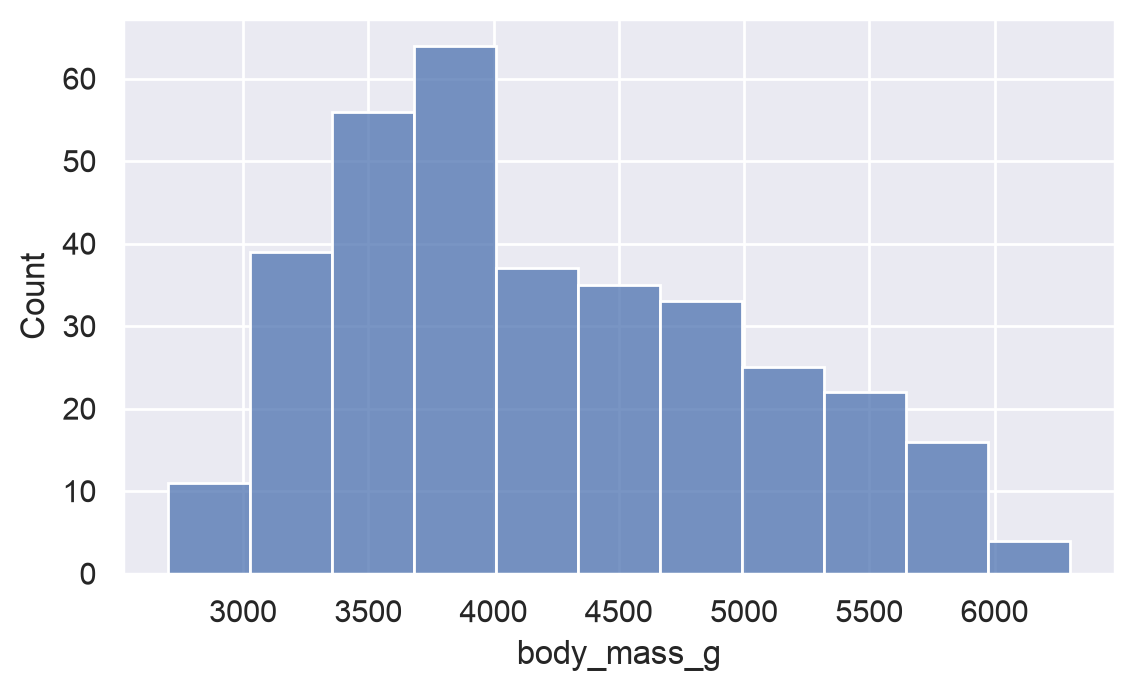

In [906]:
sns.histplot(data=df_penguins, x="body_mass_g");

`kde=True` adds a smoothed density curve on top:

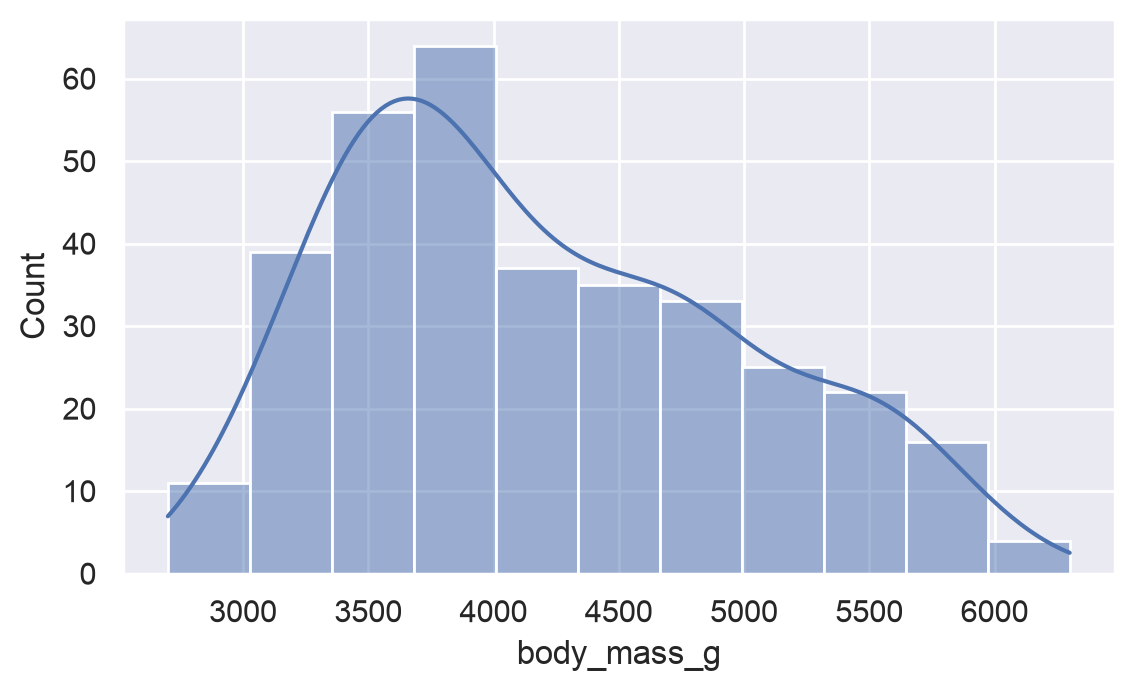

In [907]:
sns.histplot(data=df_penguins, x="body_mass_g", kde=True);

*See also:* Drawing a histogram with `histplot` (C3) · Drawing a density curve with `kdeplot` (C3)

#### Overlaying groups in a histogram

**C3.07**

`sns.histplot(..., hue='group', element='step')`

***(non-examinable)***

The `hue=` argument allows us to draw a separate histogram per group on the same axes. It is useful for comparing distributions. Alternatively, `col=` in `displot` gives each group its own panel.

In [908]:
# display the example data
df_penguins[["body_mass_g", "island"]].head()

,body_mass_g,island
0,3750.0,Torgersen
1,3800.0,Torgersen
2,3250.0,Torgersen
3,NaN,Torgersen
4,3450.0,Torgersen


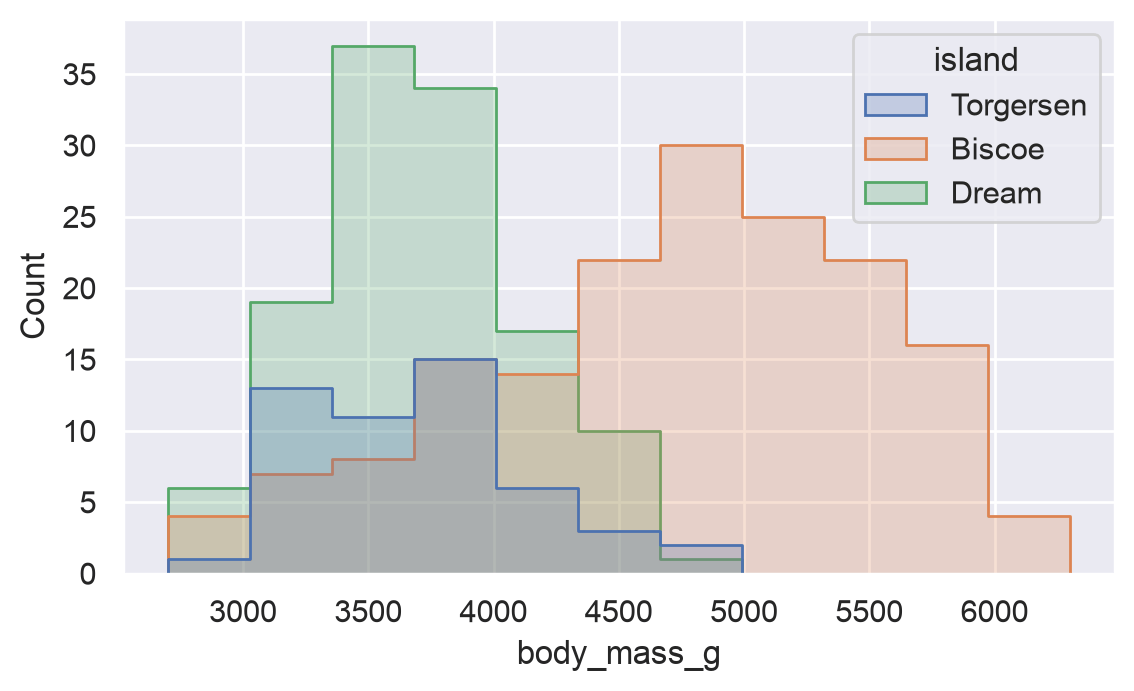

In [909]:
sns.histplot(data=df_penguins, x="body_mass_g", hue="island", element="step");

*See also:* Drawing a histogram with `histplot` (C3) · Drawing small multiples with facets (C3) · Drawing a density curve with `kdeplot` (C3)

#### Normalising a histogram

**C3.08**

`sns.histplot(..., stat='density' / 'probability')`

***(non-examinable)***

The `stat=` argument allows us to show density or probability instead of counts. It is useful for comparing groups of different sizes and for overlaying a theoretical curve. Alternatively, matplotlib's `density=True`.

In [910]:
# display the example data
df_penguins[["body_mass_g"]].head()

,body_mass_g
0,3750.0
1,3800.0
2,3250.0
3,NaN
4,3450.0


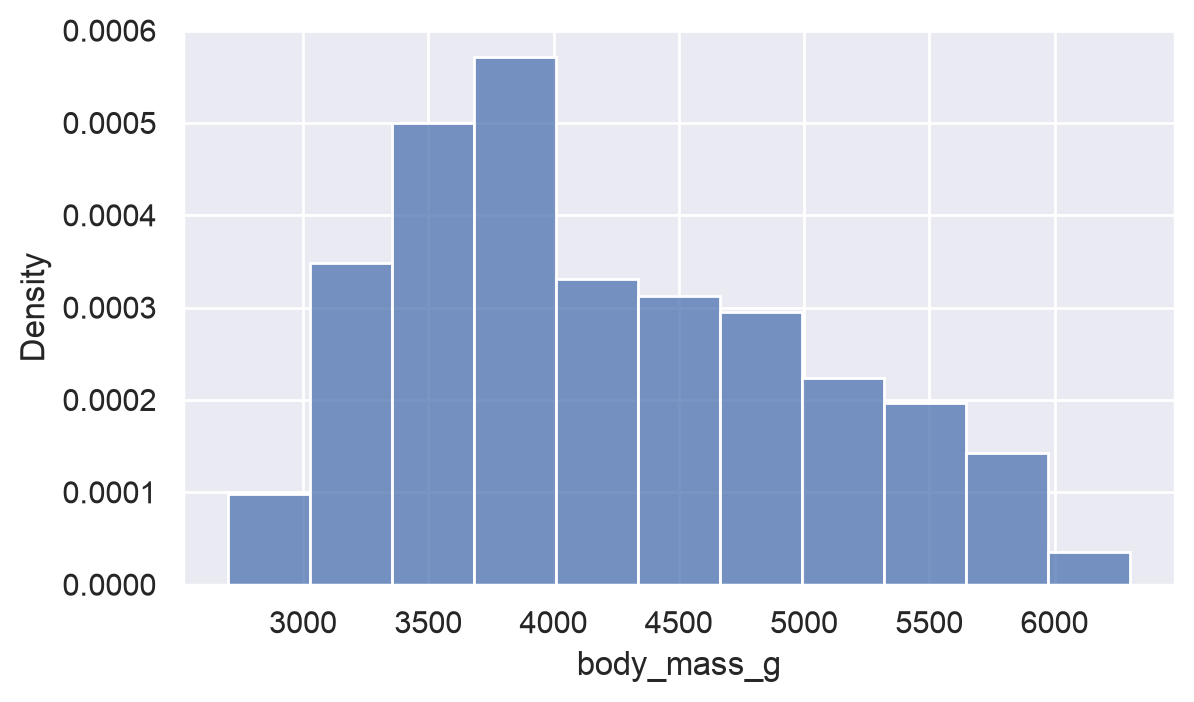

In [911]:
sns.histplot(data=df_penguins, x="body_mass_g", stat="density");

*See also:* Drawing a histogram with `histplot` (C3)

#### Drawing a density curve with `kdeplot`

**C3.09**

`sns.kdeplot(data=df, x='col', hue='group')`

***(non-examinable)***

The `sns.kdeplot()` function allows us to draw a smooth estimate of the distribution without bars. It is useful for comparing several groups cleanly. Alternatively, `histplot(kde=True)` shows bars as well.

In [912]:
# display the example data
df_penguins[["body_mass_g", "species"]].head()

,body_mass_g,species
0,3750.0,Adelie
1,3800.0,Adelie
2,3250.0,Adelie
3,NaN,Adelie
4,3450.0,Adelie


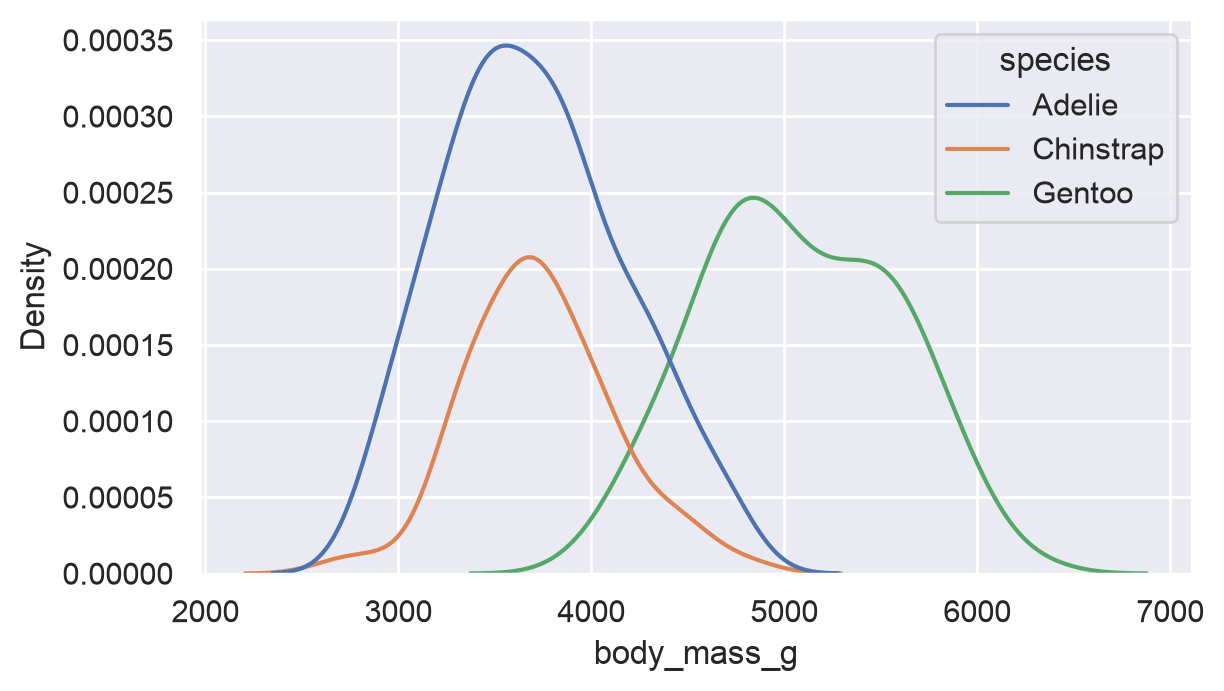

In [913]:
sns.kdeplot(data=df_penguins, x="body_mass_g", hue="species");

*See also:* Adding a smooth density curve (C3) · Drawing a histogram with `histplot` (C3)

#### Drawing a cumulative distribution with `ecdfplot`

**C3.10**

`sns.ecdfplot(data=df, x='col')`

***(non-examinable)***

The `sns.ecdfplot()` function allows us to plot the proportion of values at or below each x. It is useful for reading percentiles and cumulative probabilities straight off the plot. Alternatively, compute `cumsum()` of the probabilities.

In [914]:
# display the example data
df_penguins[["body_mass_g", "species"]].head()

,body_mass_g,species
0,3750.0,Adelie
1,3800.0,Adelie
2,3250.0,Adelie
3,NaN,Adelie
4,3450.0,Adelie


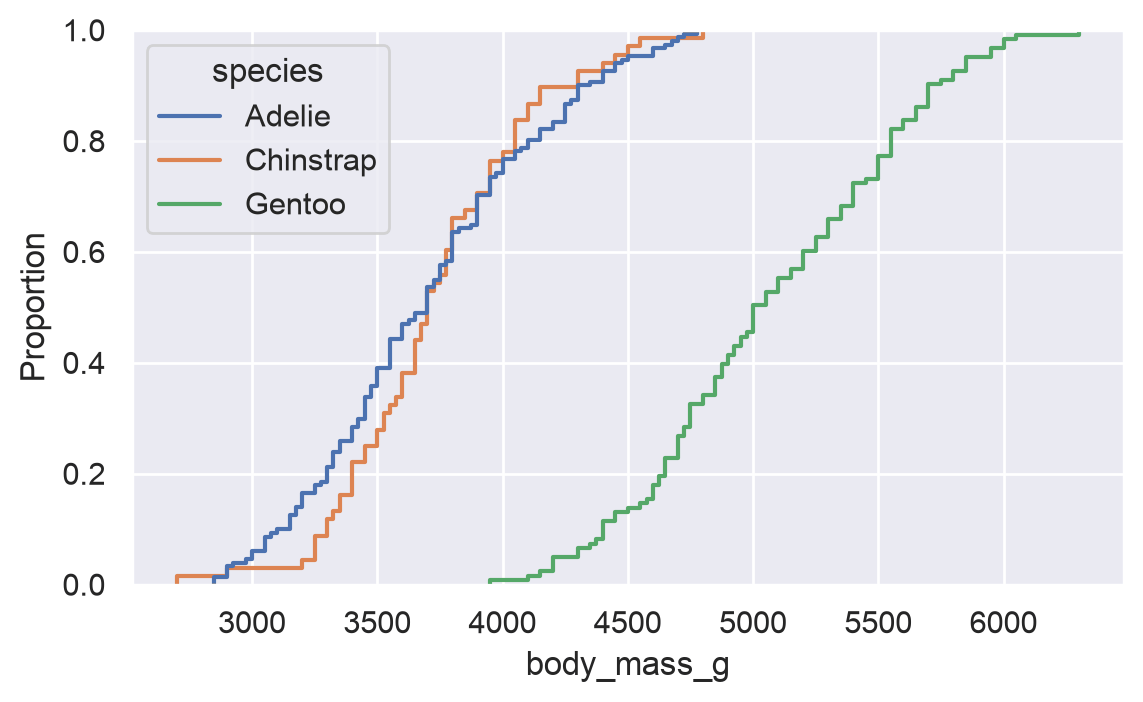

In [915]:
sns.ecdfplot(data=df_penguins, x="body_mass_g", hue="species");

*See also:* Calculating cumulative sums (B4) · Plotting a cumulative distribution (D1) · Adding a cumulative probability column (D1) · Drawing a density curve with `kdeplot` (C3)

### Plots by category

#### Drawing a box plot with `boxplot`

**C3.11**

`sns.boxplot(data=df, x='group', y='col', hue='group_2')`

The `sns.boxplot()` function allows us to compare a numeric variable across categories using medians and quartiles. It is useful for spotting differences and outliers between groups. Alternatively, `sns.violinplot` shows the whole distribution shape.

In [916]:
# display the example data
df_penguins[["species", "body_mass_g"]].head()

,species,body_mass_g
0,Adelie,3750.0
1,Adelie,3800.0
2,Adelie,3250.0
3,Adelie,NaN
4,Adelie,3450.0


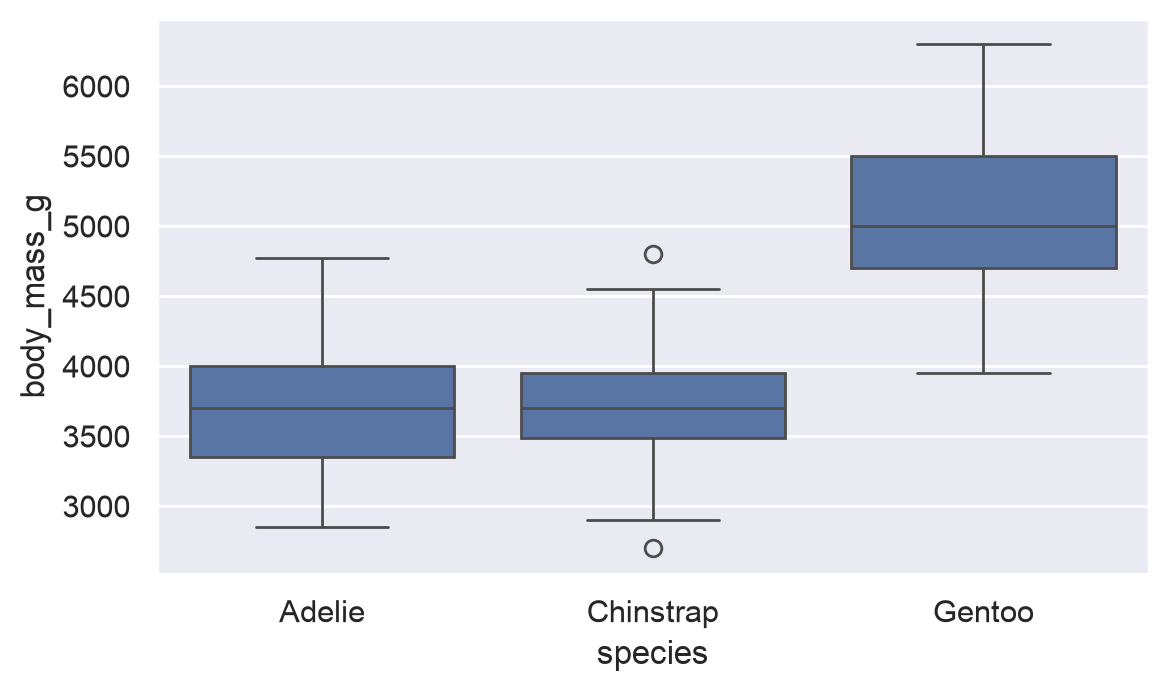

In [917]:
sns.boxplot(data=df_penguins, x="species", y="body_mass_g");

Add `hue=` to split each box by a second category:

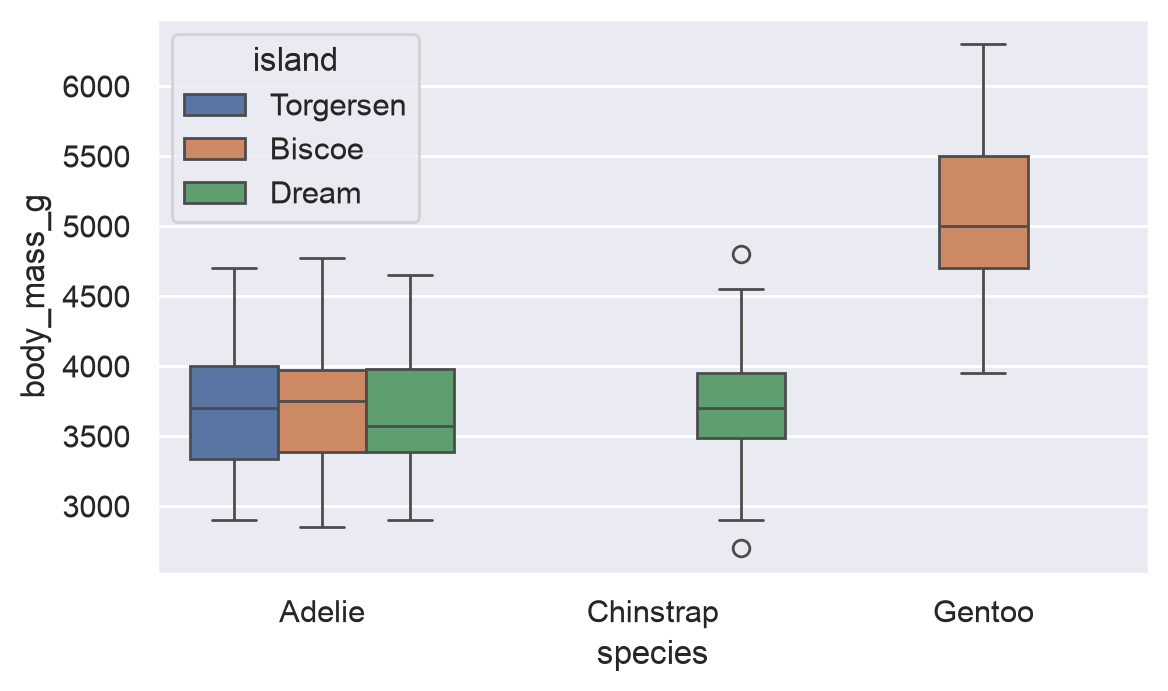

In [918]:
sns.boxplot(data=df_penguins, x="species", y="body_mass_g", hue="island");

*See also:* Drawing several box plots (C2) · Plotting a box plot with pandas (B5) · Drawing a violin plot (C3)

#### Drawing a violin plot

**C3.12**

`sns.violinplot(data=df, x='group', y='col', hue='group_2')`

The `sns.violinplot()` function allows us to show the full shape of each group's distribution, not only quartiles. It is useful when group shapes differ (for example, two humps). Alternatively, `sns.boxplot` shows the same groups with quartiles and outliers only.

In [919]:
# display the example data
df_penguins[["species", "body_mass_g"]].head()

,species,body_mass_g
0,Adelie,3750.0
1,Adelie,3800.0
2,Adelie,3250.0
3,Adelie,NaN
4,Adelie,3450.0


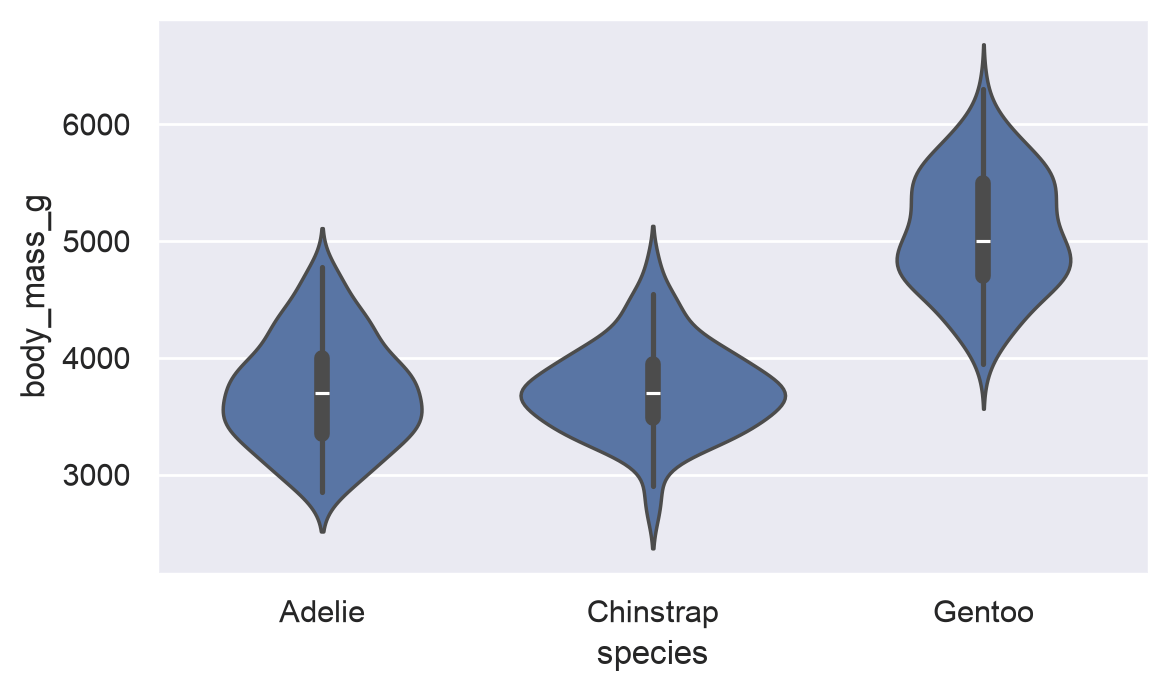

In [920]:
sns.violinplot(data=df_penguins, x="species", y="body_mass_g");

*See also:* Drawing a strip plot (C3)

#### Drawing a strip plot

**C3.13**

`sns.stripplot(..., alpha=a, jitter=False)`

The `sns.stripplot()` function allows us to draw every individual observation per category. It is useful for small datasets, where hiding points inside a box would lose information. Alternatively, `sns.swarmplot` avoids overlapping points.

In [921]:
# display the example data
df_penguins[["species", "body_mass_g"]].head()

,species,body_mass_g
0,Adelie,3750.0
1,Adelie,3800.0
2,Adelie,3250.0
3,Adelie,NaN
4,Adelie,3450.0


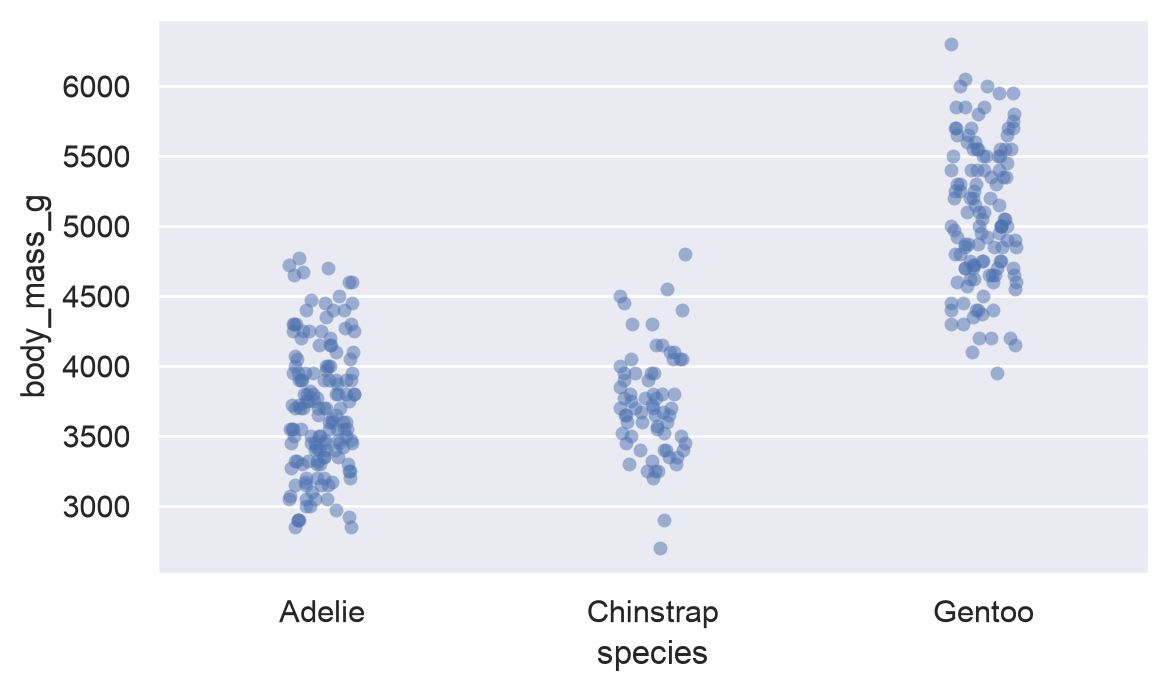

In [922]:
sns.stripplot(data=df_penguins, x="species", y="body_mass_g", alpha=0.5);

*See also:* Drawing a box plot with `boxplot` (C3) · Drawing a swarm plot (C3) · Drawing a violin plot (C3)

#### Drawing a bar plot of values

**C3.14**

`sns.barplot(data=df, x='col_1', y='col_2')`

The `sns.barplot()` function allows us to draw a bar for each category with a value that is supplied (by default the mean). It is useful for plotting a table of counts or probabilities. Alternatively, `sns.countplot` counts the rows automatically.

In [923]:
df_combos = pd.read_csv("data/3_roll_combos.csv")

In [924]:
df_totals = df_combos["total"].value_counts().to_frame().reset_index()
df_totals.head()

,total,count
0,10,27
1,11,27
2,9,25
3,12,25
4,8,21


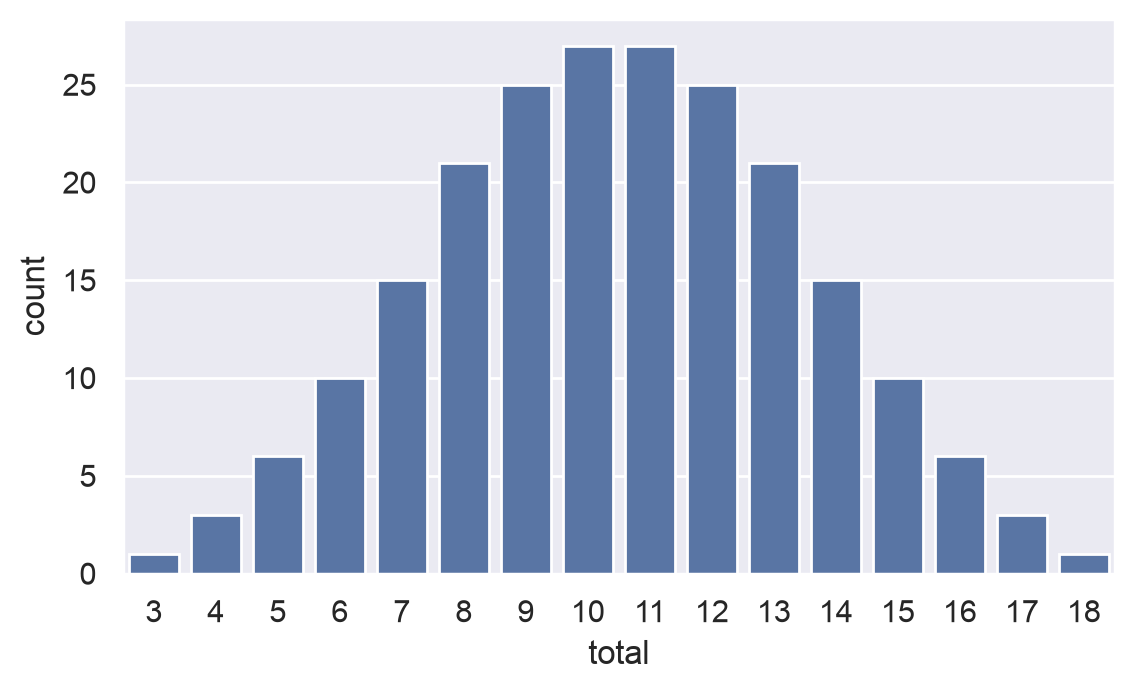

In [925]:
sns.barplot(data=df_totals, x="total", y="count");

*See also:* Counting categories with `countplot` (C3) · Drawing a bar chart (C2) · Turning counts into a table (B5) · Calculating several statistics per group (B9) · Showing the data, not only the averages (C4)

#### Counting categories with `countplot`

**C3.15**

`sns.countplot(data=df, x='col')`

***(non-examinable)***

The `sns.countplot()` function allows us to count and plot the rows in each category in one step. It is useful for quick frequency charts. Alternatively, `value_counts()` followed by `sns.barplot` also gives the table.

In [926]:
# display the example data
df_penguins[["species"]].head()

,species
0,Adelie
1,Adelie
2,Adelie
3,Adelie
4,Adelie


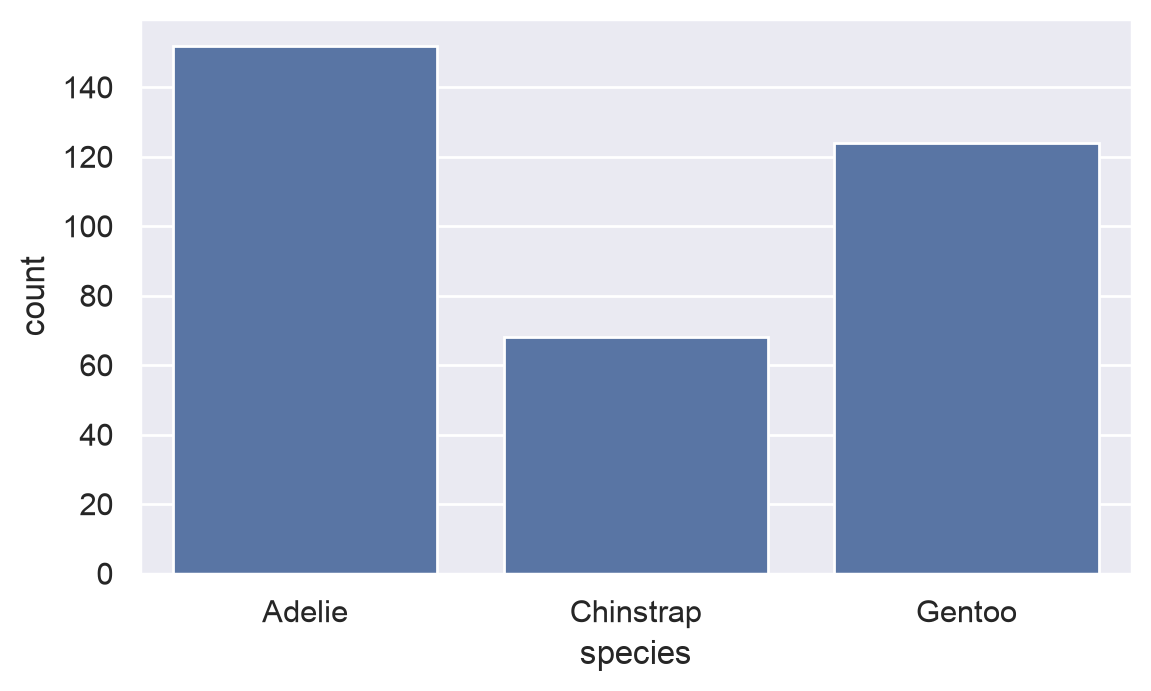

In [927]:
sns.countplot(data=df_penguins, x="species");

*See also:* Drawing a bar plot of values (C3)

#### Drawing a swarm plot

**C3.16**

`sns.swarmplot(...)`

***(non-examinable)***

The `sns.swarmplot()` function allows us to draw every observation, nudged sideways so none overlap. It is useful for small to medium datasets. Alternatively, `sns.stripplot` is quicker for large data.

In [928]:
# display the example data
df_penguins.dropna()[["species", "body_mass_g"]].head()

,species,body_mass_g
0,Adelie,3750.0
1,Adelie,3800.0
2,Adelie,3250.0
4,Adelie,3450.0
5,Adelie,3650.0


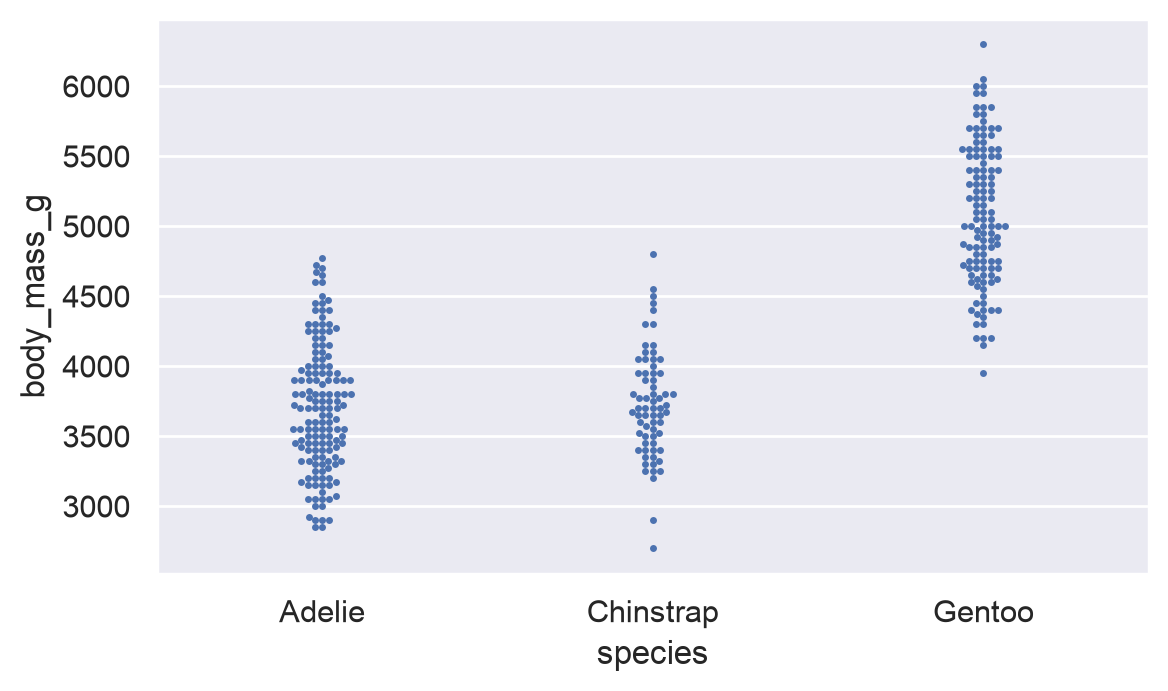

In [929]:
sns.swarmplot(data=df_penguins.dropna(), x="species", y="body_mass_g", size=2.5);

*See also:* Drawing a strip plot (C3) · Drawing a box plot with `boxplot` (C3) · Drawing a violin plot (C3)

### Relationships

#### Drawing a scatter plot with `scatterplot`

**C3.17**

`sns.scatterplot(data=df, x='col_1', y='col_2')`

The `sns.scatterplot()` function allows us to show the relationship between two numeric variables. It is useful for spotting trends, clusters and outliers. Alternatively, `plt.scatter` or `df.plot.scatter` do the same.

In [930]:
# display the example data
df_penguins[["bill_length_mm", "bill_depth_mm"]].head()

,bill_length_mm,bill_depth_mm
0,39.1,18.7
1,39.5,17.4
2,40.3,18.0
3,NaN,NaN
4,36.7,19.3


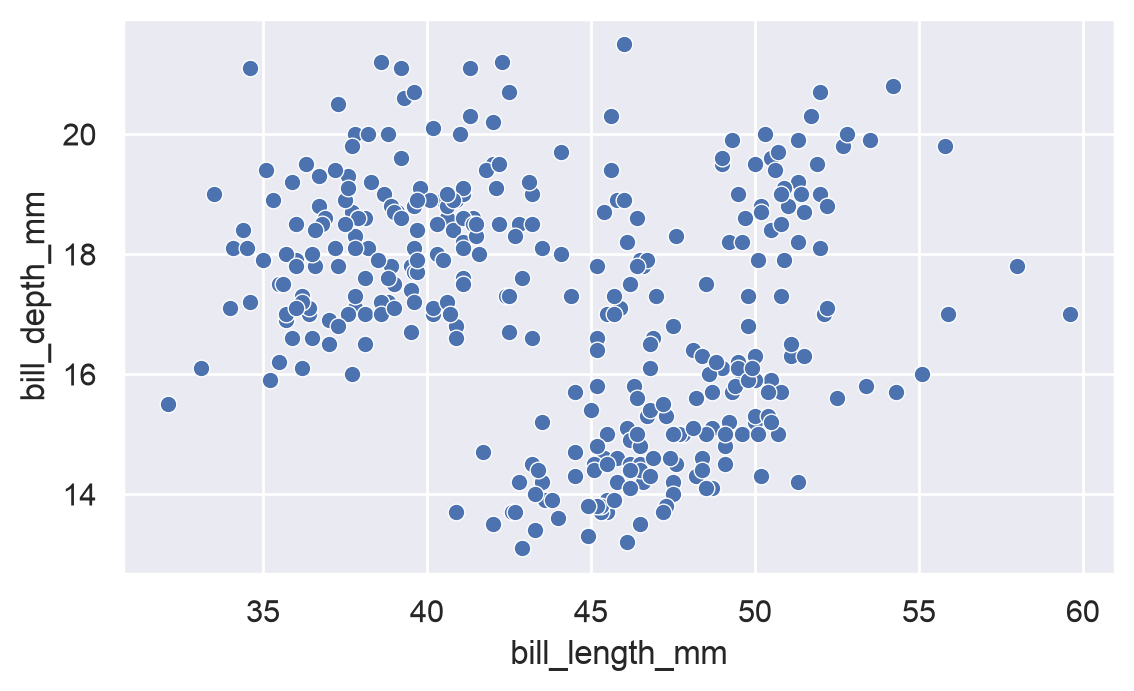

In [931]:
sns.scatterplot(data=df_penguins, x="bill_length_mm", y="bill_depth_mm");

*See also:* Plotting a scatter with pandas (B5) · Drawing a scatter plot (C2) · Colouring points by group (C3)

#### Colouring points by group

**C3.18**

`sns.scatterplot(..., hue='group')`

***(non-examinable)***

The `hue=` argument allows us to colour each point by a category. It is useful for revealing groups hidden in the overall scatter (here, three species). Alternatively, `style=` varies the marker shape instead.

In [932]:
# display the example data
df_penguins[["bill_length_mm", "bill_depth_mm", "species"]].head()

,bill_length_mm,bill_depth_mm,species
0,39.1,18.7,Adelie
1,39.5,17.4,Adelie
2,40.3,18.0,Adelie
3,NaN,NaN,Adelie
4,36.7,19.3,Adelie


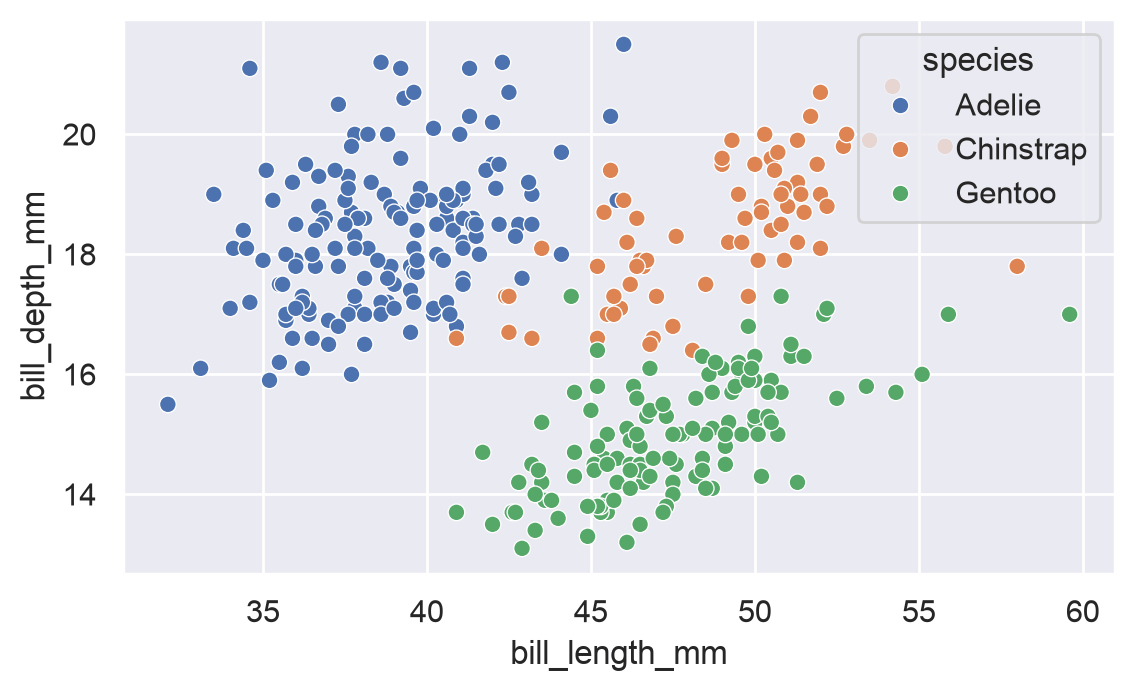

In [933]:
sns.scatterplot(data=df_penguins, x="bill_length_mm", y="bill_depth_mm", hue="species");

*See also:* Drawing a scatter plot with `scatterplot` (C3) · Colouring points by a value (C2) · Choosing a colour palette (C3)

#### Drawing a line plot

**C3.19**

`sns.lineplot(data=df, x='col_1', y='col_2', marker='o')`

The `sns.lineplot()` function allows us to join points in order along x. It is useful for trends over time or any ordered x. Alternatively, `plt.plot` draws the same line.

In [934]:
df = pd.DataFrame({"x": range(6), "y": [1, 3, 2, 5, 4, 6]})
df

,x,y
0,0,1
1,1,3
2,2,2
3,3,5
4,4,4
5,5,6


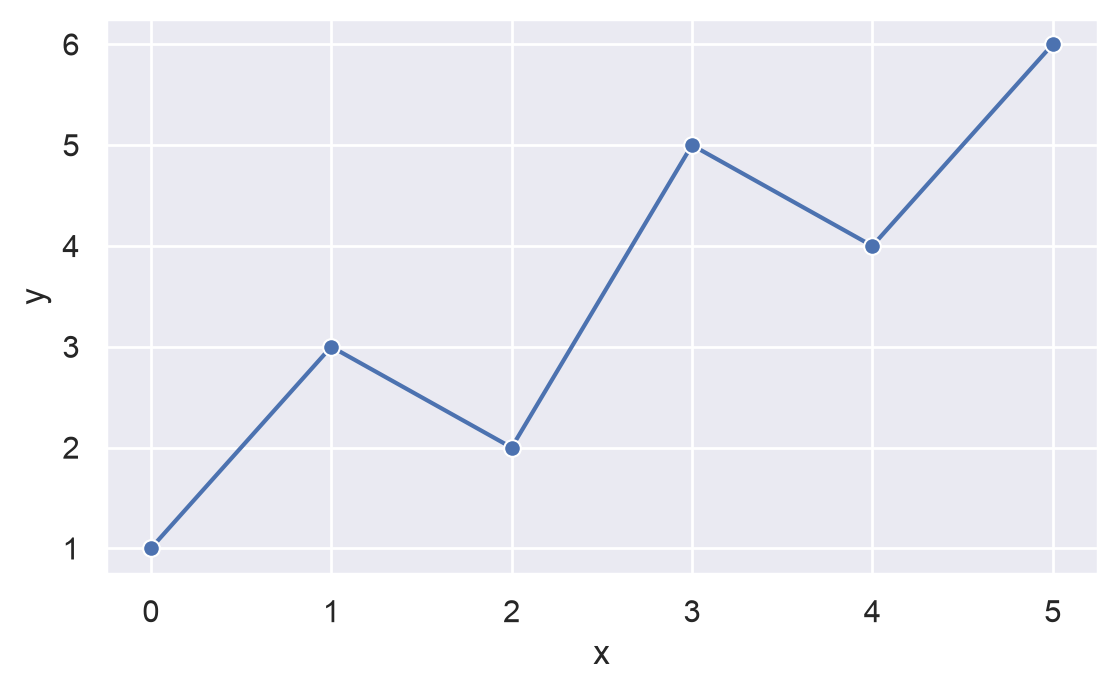

In [935]:
sns.lineplot(data=df, x="x", y="y", marker="o");

*See also:* Plotting a time series with seaborn (B8)

#### Overlaying lines on one axis

**C3.20**

`sns.lineplot(..., label=text, ax=ax); ax.legend()`

Passing the same `ax=` to several seaborn calls allows us to draw them on one set of axes. It is useful for comparing curves on the same axes. Alternatively, `hue=` on long-format data draws several lines in one call.

In [936]:
df_xs = pd.DataFrame({"x": np.linspace(-3, 3, 100)})

In [937]:
# display example dataframe
df_xs

,x
0,-3.000000
1,-2.939394
2,-2.878788
3,-2.818182
4,-2.757576
...,...
95,2.757576
96,2.818182
97,2.878788
98,2.939394


In [938]:
df_xs["a"] = stats.norm.pdf(df_xs["x"])
df_xs["b"] = stats.norm.pdf(df_xs["x"], 1, 1.5)
df_xs.head()

,x,a,b
0,-3.000000,0.004432,0.007597
1,-2.939394,0.005306,0.008455
2,-2.878788,0.006329,0.009394
3,-2.818182,0.007521,0.010420
4,-2.757576,0.008906,0.011539


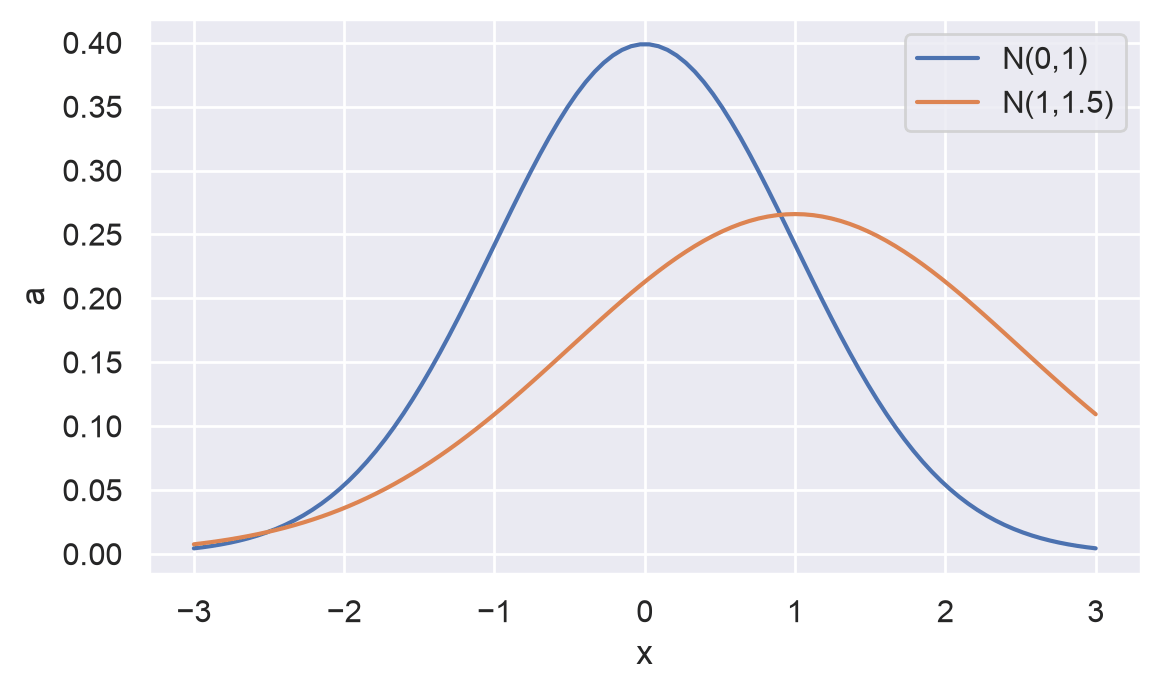

In [939]:
fig, ax = plt.subplots()
sns.lineplot(data=df_xs, x="x", y="a", label="N(0,1)", ax=ax)
sns.lineplot(data=df_xs, x="x", y="b", label="N(1,1.5)", ax=ax)
ax.legend();

*See also:* Adding a legend for several lines (C1) · Plotting a PDF from a table (D2)

#### Drawing a scatter with a fitted line

**C3.21**

`sns.regplot(data=df, x='col_1', y='col_2', line_kws={'color': c})`

The `sns.regplot()` function allows us to draw a scatter plot with a least-squares line and confidence band. It is useful for a quick look at a linear relationship. Alternatively, `stats.linregress` gives the numbers behind the line.

In [940]:
# display the example data
df_penguins[["flipper_length_mm", "body_mass_g"]].head()

,flipper_length_mm,body_mass_g
0,181.0,3750.0
1,186.0,3800.0
2,195.0,3250.0
3,NaN,NaN
4,193.0,3450.0


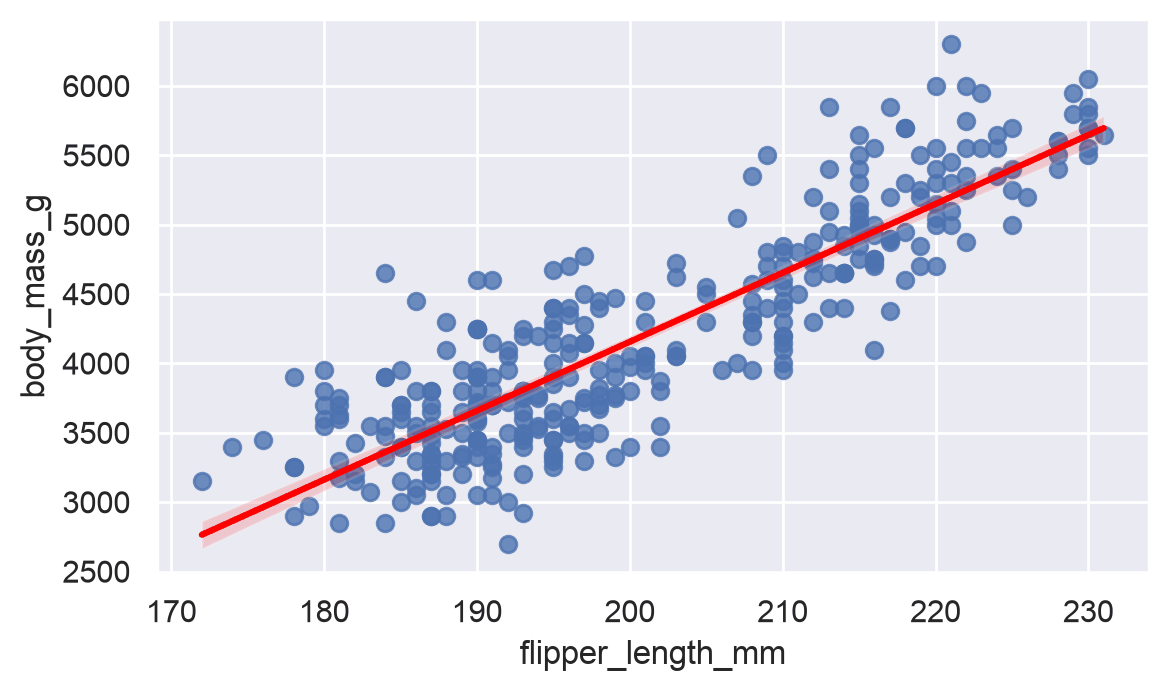

In [941]:
sns.regplot(data=df_penguins, x="flipper_length_mm", y="body_mass_g", line_kws={"color": "red"});

*See also:* Fitting a line (D5) · Passing plot options as a dictionary (A3) · Drawing a line between two points (C1) · Drawing a residual plot (C3)

#### Drawing a residual plot

**C3.22**

`sns.residplot(data=df, x='col_1', y='col_2')`

The `sns.residplot()` function allows us to plot the residuals of a straight-line fit against x. It is useful for checking the linear and equal-variance assumptions (a random cloud around 0 is good). Alternatively, calculate the residuals and draw them with `plt.scatter`, which gives full control of the plot.

In [942]:
# display the example data
df_penguins[["flipper_length_mm", "body_mass_g"]].head()

,flipper_length_mm,body_mass_g
0,181.0,3750.0
1,186.0,3800.0
2,195.0,3250.0
3,NaN,NaN
4,193.0,3450.0


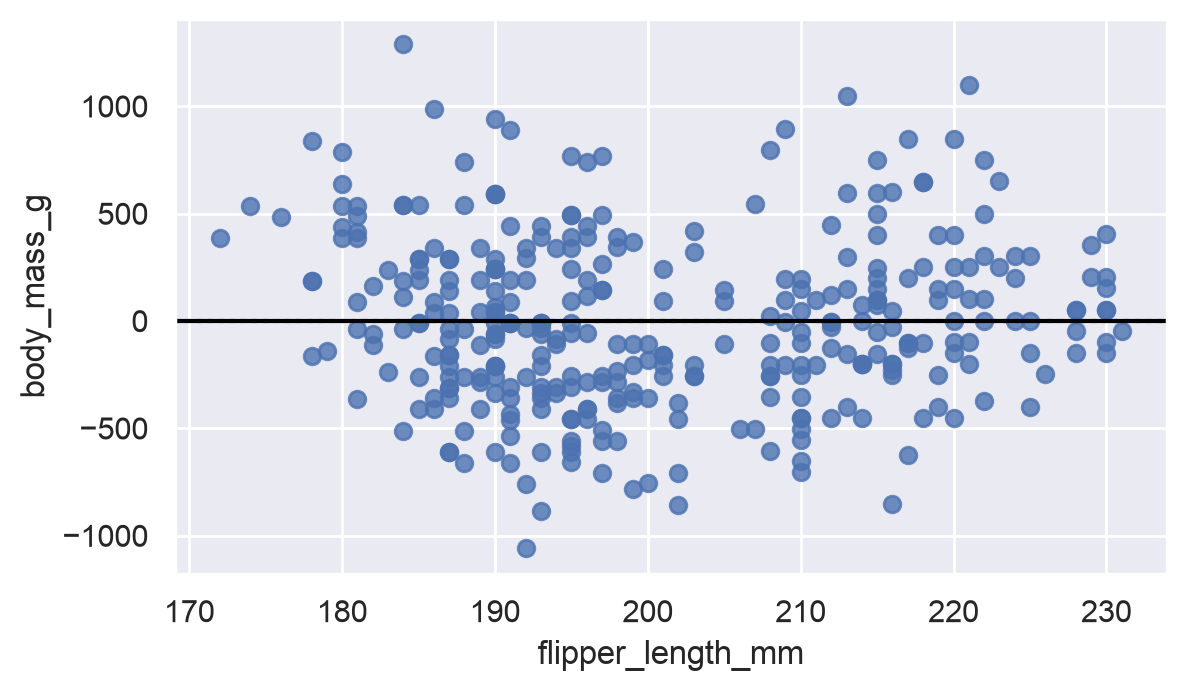

In [943]:
sns.residplot(data=df_penguins, x="flipper_length_mm", y="body_mass_g")
plt.axhline(0, color="black");

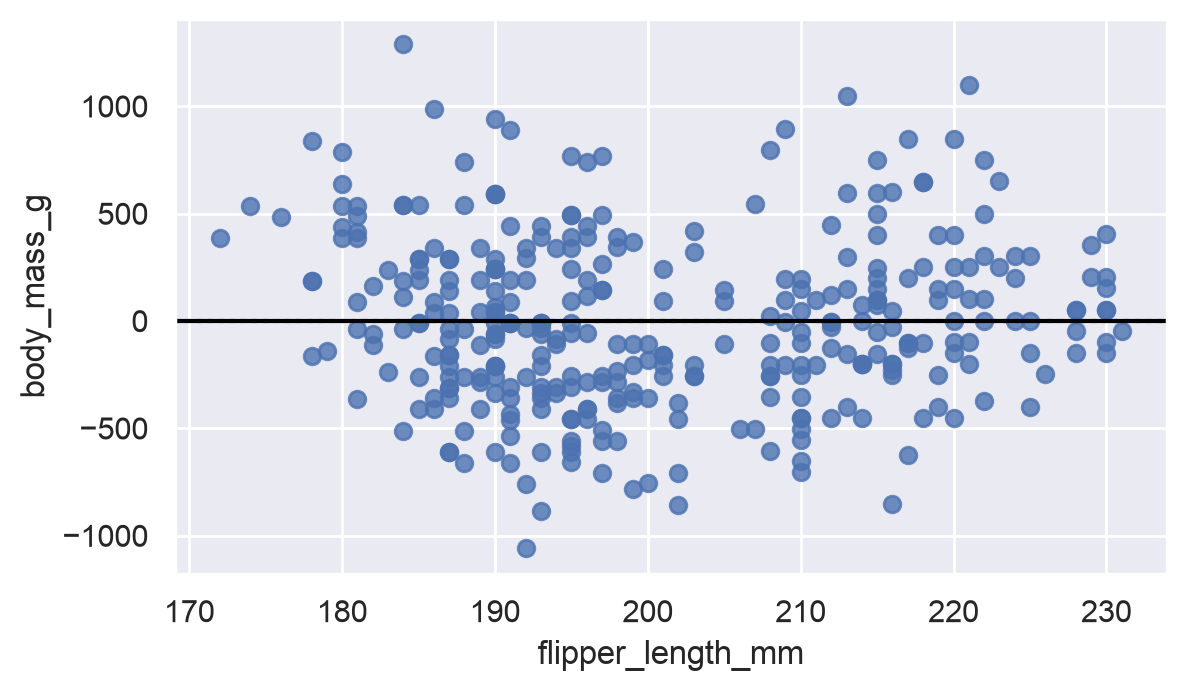

In [944]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
sns.residplot(data=df_penguins, x="flipper_length_mm", y="body_mass_g", ax=ax)
ax.axhline(0, color="black");

*See also:* Drawing a scatter plot (C2) · Residuals versus fitted values (D5) · Residual plots with seaborn (D5)

#### Plotting every pair of variables

**C3.23**

`sns.pairplot(df, hue='group')`

***(non-examinable)***

The `sns.pairplot()` function allows us to draw scatter plots of every pair of numeric columns. It is useful as a first overview of a dataset. Alternatively, plot the pairs of interest with `sns.scatterplot`.

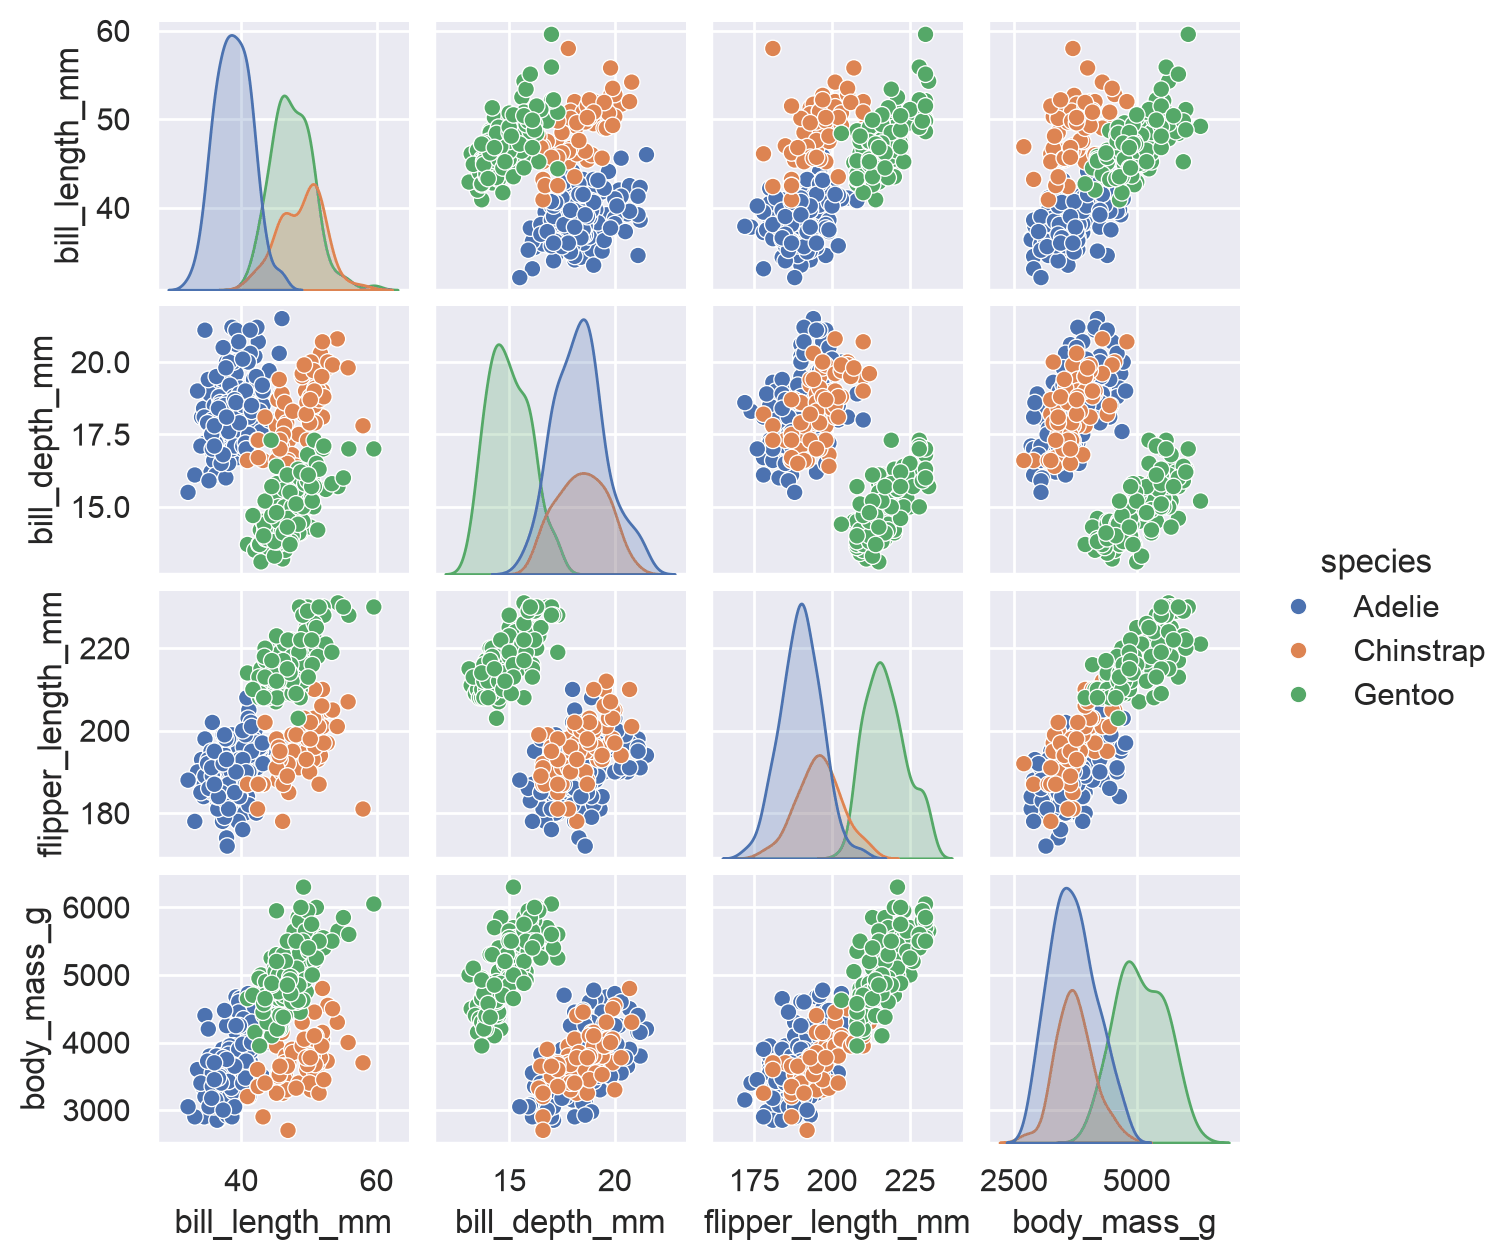

In [945]:
sns.pairplot(df_penguins, hue="species", height=1.6);

*See also:* Following an exploration checklist (B5) · Colouring points by group (C3)

#### Drawing a correlation heatmap

**C3.24**

`sns.heatmap(df.corr(numeric_only=True), annot=True)`

***(non-examinable)***

The `sns.heatmap()` function allows us to colour a table of numbers, such as a correlation matrix. It is useful for spotting related variables at a glance. Alternatively, print `df.corr()` as a table.

In [946]:
df_corr = df_penguins.corr(numeric_only=True).round(2)
df_corr

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,-0.24,0.66,0.60
bill_depth_mm,-0.24,1.00,-0.58,-0.47
flipper_length_mm,0.66,-0.58,1.00,0.87
body_mass_g,0.60,-0.47,0.87,1.00


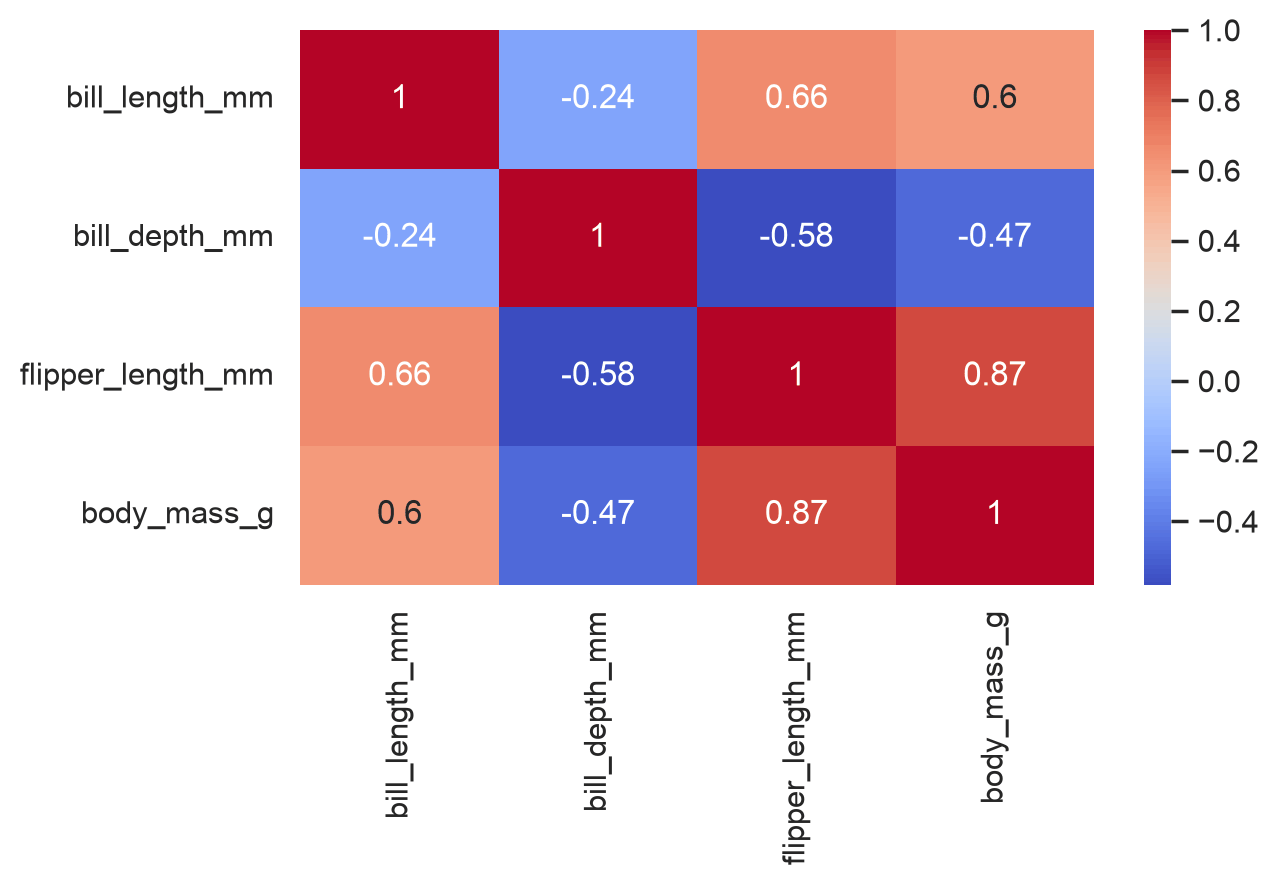

In [947]:
sns.heatmap(df_corr, annot=True, cmap="coolwarm");

*See also:* Checking the correlation first (D5) · Drawing a scatter plot with `scatterplot` (C3) · Plotting every pair of variables (C3)

#### Drawing small multiples with facets

**C3.25**

`sns.displot(..., col='group'), sns.catplot(..., kind='box')`

***(non-examinable)***

Figure-level functions such as `displot`, `catplot` and `relplot` with `col=` allow us to draw one panel per category. It is useful for comparing many groups without overlap. Alternatively, loop over groups and use `plt.subplots`.

In [948]:
# display the example data
df_penguins[["body_mass_g", "species"]].head()

,body_mass_g,species
0,3750.0,Adelie
1,3800.0,Adelie
2,3250.0,Adelie
3,NaN,Adelie
4,3450.0,Adelie


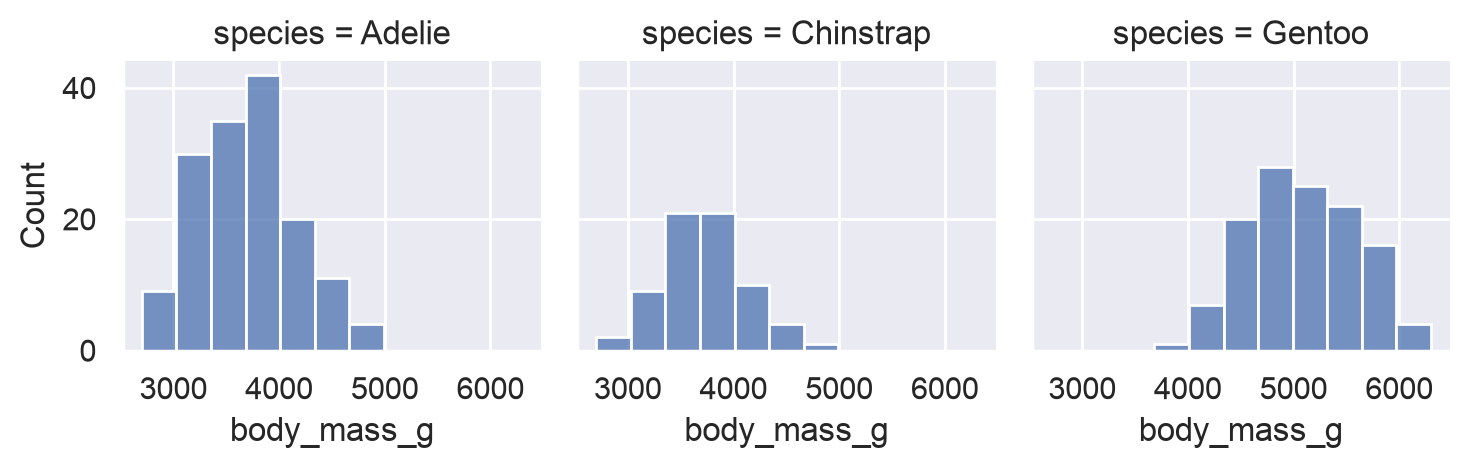

In [949]:
sns.displot(data=df_penguins, x="body_mass_g", col="species", height=2.5);

*See also:* Overlaying groups in a histogram (C3)

#### Choosing a colour palette

**C3.26**

`palette='Set2'`

***(non-examinable)***

The `palette=` argument allows us to choose the colours a seaborn plot uses. It is useful for readability, or colour-blind-friendly output. Alternatively, `sns.set_palette()` sets one for the whole notebook.

In [950]:
# display the example data
df_penguins[["species", "body_mass_g"]].head()

,species,body_mass_g
0,Adelie,3750.0
1,Adelie,3800.0
2,Adelie,3250.0
3,Adelie,NaN
4,Adelie,3450.0


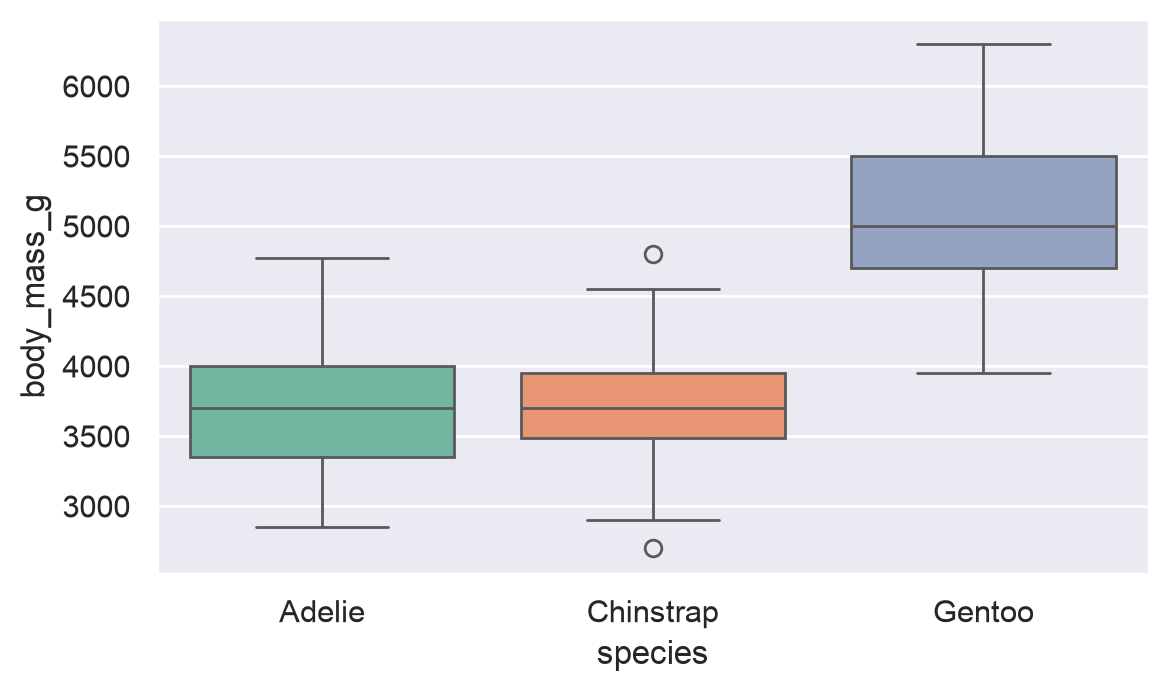

In [951]:
sns.boxplot(data=df_penguins, x="species", y="body_mass_g", hue="species", palette="Set2", legend=False);

*See also:* Setting a seaborn theme (C3) · Colouring points by a value (C2) · Drawing a box plot with `boxplot` (C3) · Colours that every reader can tell apart (C4)